# Observer trajectories, physical scales, and what static calibration fixes

The black-hole application becomes more informative when its prepared source, clock, noise mode, and resource comparison are specified separately. This notebook does three things:

1. Recomputes stationary Hawking throughput and mode occupations from a packaged scalar transmission grid, while preserving the paper's engineered five-carrier schedule.
2. Compares the original one-pole response with a passive LC two-port and computes a reference-safe **asymptotic** packet error.
3. Replays a fixed effective outgoing channel for static and infalling receivers on every frozen Hayden–Preskill source, under three different budgets.

The last calculation is a one-way, number-preserving vacuum-channel model with frozen transmitted packets. It is not a local 3+1-dimensional Schwarzschild detector calculation or a prediction of horizon crossing. The stationary LC test does not supply that missing moving-field embedding.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, str(Path.cwd() / 'code'))
from receiver_extensions.paths import DATA, verify_inputs, save_result
manifest = verify_inputs()
print('Packaged input hashes verified:', ', '.join(manifest))


Packaged input hashes verified: frozen_inputs.npz, scalar_flux_grid_384.npz


## Prepared carriers and native Hawking throughput are different resources

In units $G=c=\hbar=k_B=M=1$, the detector at $r=20M$ has lapse $z=\sqrt{0.9}$. The supplied packet peaks remain at proper times $(28,40,52,64,76)M$, with a $120M$ proper deadline. Their coordinate separation is $12/z$.

The grid below contains one real massless scalar with $\ell=0,1,2$. Flux integrals have degeneracy $2\ell+1$ and Bose occupation $(e^{8\pi M\omega}-1)^{-1}$. A ten-copy row illustrates the explicit multiplicity if ten distinguishable scalar rail channels are treated as independent fields. Neither entropy bits nor emitted quanta are automatically logical diary carriers. The entropy rate multiplied by an interval is a stationary thermodynamic budget, not exact finite-window entropy.


In [2]:
from receiver_extensions.physical_scales import calculate as physical_scales
scales = physical_scales()
columns = ['sector','field_copies','power_infinity','photon_mean_interval_coordinate',
           'entropy_bit_interval_coordinate','expected_photons_in_120_proper','stationary_entropy_budget_in_120_proper']
display(pd.DataFrame(scales['flux_rows'])[columns].round(8))
print('Prepared peak spacing: proper =',scales['proper_peak_spacing'],', coordinate =',scales['coordinate_peak_spacing'])
print('Prepared deadline: proper =',scales['proper_window'],', coordinate =',scales['coordinate_window'])


,sector,field_copies,power_infinity,photon_mean_interval_coordinate,entropy_bit_interval_coordinate,expected_photons_in_120_proper,stationary_entropy_budget_in_120_proper
0,ell0,1,0.000067,1571.836855,217.228108,0.080473,0.582296
1,ell0,10,0.000670,157.183685,21.722811,0.804734,5.822962
2,ell0to2,1,0.000074,1504.091424,199.923680,0.084098,0.632697
3,ell0to2,10,0.000744,150.409142,19.992368,0.840980,6.326970


Prepared peak spacing: proper = 12.0 , coordinate = 12.649110640673518
Prepared deadline: proper = 120.0 , coordinate = 126.49110640673518


For one scalar, the mean quantum interval is about $1504M$ and the stationary entropy-bit interval about $200M$. The prepared register is therefore not an unqualified sample of native Hawking output. A universal “17-fold compression” would depend on field count, partial waves, the choice of time, and the unsupported identification of an entropy bit with a logical carrier.

## Specify the noise mode and the clock

The source Gaussian mode $q(\omega)$ and the normalized transmitted mode proportional to $q(\omega)\Gamma_0(\omega)$ have different background occupations. The table evaluates both, with and without the explicitly modeled aperture attenuation $\eta=0.6336$. These are asymptotic mode occupations, not a universal local detector noise rate. In the Unruh state the UP sector is thermally populated while the IN sector is vacuum; an equilibrium Tolman bath is a different state assumption.

A temperature-normalized activation realization would have coordinate width $8M$. A static-acceleration/boost normalization at $20M$ instead gives $800M$. The paper's laboratory normalization gives a proper width $40M$. KMS analyticity alone fixes neither the receiver coupling nor its kinetic hazard.


In [3]:
p=scales['packet']; c=scales['clocks']
display(pd.DataFrame([
    {'mode':'Source Gaussian','occupation':p['gaussian_mode_thermal_occupation'],'after_eta':p['gaussian_mode_thermal_occupation_after_aperture']},
    {'mode':'Normalized transmitted','occupation':p['normalized_transmitted_mode_thermal_occupation'],'after_eta':p['transmitted_mode_thermal_occupation_after_aperture']}
]).set_index('mode').round(9))
display(pd.DataFrame([
    {'clock':'Temperature-normalized','proper_width_r20':c['thermal_clock_char_proper'],'coordinate_width':c['thermal_clock_char_coordinate']},
    {'clock':'Static acceleration/boost','proper_width_r20':c['boost_clock_char_proper'],'coordinate_width':c['boost_clock_char_coordinate']},
    {'clock':'Laboratory Omega=0.025','proper_width_r20':c['lab_Omega025_char_proper'],'coordinate_width':c['lab_Omega025_char_coordinate']}
]).set_index('clock'))
print('Packet-averaged greybody transmission:',p['transmission'])


,occupation,after_eta
mode,,
Source Gaussian,0.014661,0.009289
Normalized transmitted,0.013029,0.008255


,proper_width_r20,coordinate_width
clock,,
Temperature-normalized,7.589466,8.000000
Static acceleration/boost,758.946638,800.000000
Laboratory Omega=0.025,40.000000,42.163702


Packet-averaged greybody transmission: 0.7222117972236304


## Static passive implementation: a bounded asymptotic comparison

For the positive-frequency packet, compare

$$H_0(\omega)=\frac{1}{1-2i(\omega-\Omega)/\kappa},\qquad
H_{LC}(\omega)=\frac{\kappa\omega}{\kappa\omega-i(\omega^2-\Omega^2)}.$$

Here $\Omega=0.16/z$ and $\kappa=0.515$. The LC model has both poles and a unitary two-port scattering matrix. We compare the complete transmitted/reflected one-photon states in the same output phase convention, including common greybody and aperture dilations where stated. For carrier overlap $c$, the five-carrier reference-safe pure-isometry bound is $\sqrt{1-|c|^{10}}$. It bounds subsequent measurement-score differences by contractivity.

This statement concerns asymptotic scattering of prepared packets. It does not equate finite-deadline memory possession, switch-on transients, or bare cavity energy with a photon probability.


In [4]:
from receiver_extensions.static_network import diagnostic, reference_certificate
network = diagnostic(); reference = reference_certificate()
display(pd.DataFrame([network['transmitted_gaussian']],index=['Transmitted packet']).T)
display(pd.DataFrame(reference['certificate'])[['scope','one_carrier_global_trace_distance','five_carrier_global_trace_distance']].set_index('scope'))
assert network['unitarity_diagonal_residual']<1e-12
assert network['unitarity_offdiagonal_residual']<1e-12
print('Normalized network parameters:',network['network_parameters_normalized'])
print('Two-port unitarity residual:',network['unitarity_diagonal_residual'])


,Transmitted packet
legacy_transmitted_probability,0.984979
lc_transmitted_probability,0.985276
weighted_complex_amplitude_rms,0.019309
twoport_scattering_vector_rms,0.027307
conditional_output_mode_overlap,0.999735


,one_carrier_global_trace_distance,five_carrier_global_trace_distance
scope,,
conditional_transmitted_packet,0.025011,0.055891
common_greybody,0.021814,0.048755
common_greybody_and_eta,0.017778,0.039740


Normalized network parameters: {'C': 1.0, 'L': 35.15625, 'each_port_Z': 3.883495145631068}
Two-port unitarity residual: 5.551115123125783e-16


The packet-weighted transmitted probabilities are close, but the full complex scattering difference matters. The five-carrier bound is about $0.0559$ conditional on the transmitted packet and $0.0398$ after the common upstream loss. Similar intensities alone would not establish this reference-safe statement.

Static calibration also fails to identify how a device couples away from its calibration worldline. A finite passive two-mode witness below has identical complete static dynamics for $g_1(r)=g_0$ and $g_2(r)=g_0r/20$ at $r=20M$, but different capture along infall. Both single-particle Hamiltonians stay positive. These are distinct possible spatial embeddings, not two predictions for one fully specified apparatus.


In [5]:
embedding = reference['embedding_nonidentifiability_witness']
display(pd.DataFrame([{k:embedding[k] for k in ['minimum_single_particle_eigenvalue','proper_duration',
    'static_both_capture_probability','moving_profile1_capture_probability','moving_profile2_capture_probability']}]))


,minimum_single_particle_eigenvalue,proper_duration,static_both_capture_probability,moving_profile1_capture_probability,moving_profile2_capture_probability
0,0.148655,38.392466,0.482455,0.482455,0.227257


## The effective infalling calculation and its three budgets

The frozen input envelopes feed a passive receiver with $\eta=0.6336$, $\kappa=0.515$, and $\Omega=0.16/z$. The effective channel maps the static retarded coordinate $q$ to infalling proper time $\tau$ by $u(\tau)=\sqrt{dq/d\tau}\,u_0(q(\tau))$. The square root preserves temporal-mode norm. Infall begins at $20M$ from rest at infinity and ends outside the horizon, at $6M$ or $4M$.

We compare:

- **Equal proper duration:** fixed static and fixed infalling hardware operate for the same duration, but receive different retarded support.
- **Equal retarded support:** the static receiver is allowed the longer interval needed to see the same incoming packet portion.
- **Adaptive hardware:** along infall, both $\kappa$ and $\Omega$ scale with $dq/d\tau$. This restores the static input-output calculation under time reparametrization, while spending a different control/bandwidth budget.

Equal duration does not also match total incident energy, aperture, or every apparatus resource. Each row reports extrema of statewise certificates over all 32 sources, with full early radiation available.


In [6]:
from receiver_extensions.infalling import run
baseline = run('baseline',.05)
trajectory_rows=[]
for radius,case in baseline['cases'].items():
    for name in ['infall_fixed','static_same_proper_duration','static_same_retarded_support','infall_adaptive']:
        row=case[name]; score=row['scores']['full_early']
        trajectory_rows.append(dict(r_end=radius,receiver=name,proper_duration=row['proper_duration'],
                                    full_early_floor=score['bell_lower_min'],full_early_ceiling=score['bell_upper_max'],
                                    no_early_ceiling=row['scores']['no_early']['bell_upper_max'],balance_error=row['max_balance_error']))
display(pd.DataFrame(trajectory_rows).set_index(['r_end','receiver']).round(9))


proper_duration  ...  balance_error
r_end receiver                                       ...               
6.0   infall_fixed                        35.235499  ...            0.0
      static_same_proper_duration         35.235499  ...            0.0
      static_same_retarded_support        56.246177  ...            0.0
      infall_adaptive                     35.235499  ...            0.0
4.0   infall_fixed                        38.392466  ...            0.0
      static_same_proper_duration         38.392466  ...            0.0
      static_same_retarded_support        64.505593  ...            0.0
      infall_adaptive                     38.392466  ...            0.0

[8 rows x 5 columns]

At $r=4M$, fixed infall guarantees at least $0.6525$ while every decoder for the equal-proper-duration static interface is below $0.5949$; the bounds separate on every tested source. At $r=6M$ the analogous bounds are above $0.6101$ and below $0.5510$. However, allowing the static receiver the same retarded support increases every carrier's collection probability. Adaptive infall reproduces that longer static calculation to numerical tolerance. These statements identify the comparison budget rather than a universal advantage of infall.


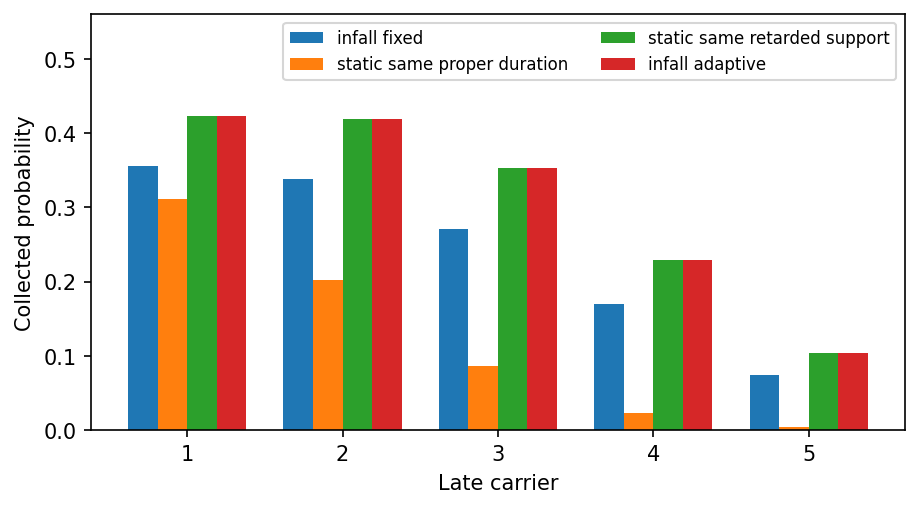

r=4 geometry and control cost: {'r_end': 4.0, 'proper_duration': np.float64(38.39246596925014), 'static_equivalent_duration': 64.50559302747537, 'clock_rate_initial': 1.3874258867227929, 'clock_rate_final': 3.239007382600897, 'adaptive_kappa_final': 1.668088802039462, 'adaptive_omega_final': 0.5462741699796945}
Adaptive/static and equal-support controls: {'adaptive_vs_static_p': 2.0022872249114698e-13, 'input_norm_equal_support': 4.708455847435289e-13}


In [7]:
case=baseline['cases']['4.0']
labels=['infall_fixed','static_same_proper_duration','static_same_retarded_support','infall_adaptive']
fig,ax=plt.subplots(figsize=(7,3.6));x=np.arange(5)
for index,label in enumerate(labels):
    ax.bar(x+(index-1.5)*.19,case[label]['p'],width=.19,label=label.replace('_',' '))
ax.set(xticks=x,xticklabels=np.arange(1,6),xlabel='Late carrier',ylabel='Collected probability',ylim=(0,.56))
ax.legend(fontsize=8,ncol=2);plt.show()
print('r=4 geometry and control cost:',case['geometry'])
print('Adaptive/static and equal-support controls:',case['control_errors'])


The grouped bars show how equal duration and equal incoming support yield different experiments. The adaptive and equal-support static bars coincide because both the coupling and resonance are rescaled, not because motion has no physical effect.

## Solver and input refinement

The next cell reruns every comparison with half the maximum integration step and then with the independently refined physical packet grid. Energy balance, strict recovery separation, componentwise equal-support comparisons, and adaptive covariance are asserted inside the solver. The refinements test numerical stability of this specified effective model; they do not validate a missing local-field detector theory.


In [8]:
solver_refined=run('baseline',.025)
input_refined=run('physical_refined',.05)
convergence=[]
for radius in baseline['cases']:
    for name in labels:
        p0=np.asarray(baseline['cases'][radius][name]['p'])
        solver=float(np.max(abs(p0-np.asarray(solver_refined['cases'][radius][name]['p']))))
        physical=float(np.max(abs(p0-np.asarray(input_refined['cases'][radius][name]['p']))))
        convergence.append(dict(r_end=radius,receiver=name,solver_refinement=solver,physical_input_refinement=physical))
display(pd.DataFrame(convergence).set_index(['r_end','receiver']))
assert max(row['solver_refinement'] for row in convergence)<1e-8
assert max(row['physical_input_refinement'] for row in convergence)<1e-4
result=dict(physical_scales=scales,static_network=network,asymptotic_reference_certificate=reference,
            trajectory_runs=[baseline,solver_refined,input_refined],convergence=convergence)
print('Computed evidence saved:',save_result('observer_trajectories_and_scales.json',result))


solver_refinement  physical_input_refinement
r_end receiver                                                                  
6.0   infall_fixed                       1.082467e-14               2.261628e-08
      static_same_proper_duration        1.149081e-14               6.892266e-09
      static_same_retarded_support       1.604272e-14               8.877909e-09
      infall_adaptive                    8.604228e-15               8.877908e-09
4.0   infall_fixed                       1.745548e-13               3.404181e-08
      static_same_proper_duration        1.249001e-14               7.220490e-09
      static_same_retarded_support       1.737499e-14               8.852142e-09
      infall_adaptive                    2.088330e-13               8.852130e-09

Computed evidence saved: outputs/runs/integration_trajectory_final_20261105/extensions/observer_trajectories_and_scales.json


The reusable inputs contain the actual 32-source information tables and both propagated packet grids. Their hashes are checked before calculation; upstream regeneration remains available in the original notebook. No research-only radial detector backend or unretained 40-record noise table is needed for these results.

The primary antecedents and qualified manuscript claims are recorded in the paper's field-audit references. The effective input-output covariance uses established passive receiver-control mathematics. The retained contribution is the explicit budget comparison and its source-resolved recovery certificates, together with a stated boundary between static calibration and a fully specified moving apparatus.
